# Household Electricity Consumption Analysis
**Python Programming — Individual Case Study**

| | |
|---|---|
| **Name** | Manjari Majumdar |
| **Roll Number** | RA2411005010075 |
| **Programme** | B.Tech Electrical and Electronics Engineering, SRMIST |
| **Dataset** | RA2411005010075_ManjariMajumdar_Dataset.csv (simulated, 1–30 September 2026) |

## 1. Problem Statement
Households usually see only one number every month: the total electricity bill. They do not know **which appliances consume the most energy**, **which days are unusually heavy**, or **how slab-based tariffs push the bill up** once consumption crosses a limit. Without this breakdown it is hard to decide where to save energy.

This case study uses Python to analyse 30 days of appliance-wise electricity consumption for a household and turn the raw readings into useful information.

## 2. Objectives
1. Read and organise daily appliance-wise consumption data (kWh) from a CSV file.
2. Find the total and average consumption of each appliance and its share of the total.
3. Identify high-usage days that exceed a chosen threshold.
4. Compare average weekday and weekend consumption.
5. Estimate the monthly bill using a slab-based tariff.
6. Visualise the results and draw conclusions for reducing energy use.

## 3. Dataset Description
- **Source:** Simulated by the student to represent a typical 2BHK household in Chennai (30 days, September 2026). Values were generated with realistic ranges: higher AC use on weekends and during a hot spell in the second week, and washing machine use on Wednesdays and weekends.
- **Rows:** 30 (one per day)  **Columns:** 8
- **Columns:** `Date`, `Day`, and daily energy (kWh) for `AC`, `Refrigerator`, `Water_Heater`, `Lights_Fans`, `Washing_Machine`, `Laptop_TV`.

## 4. Methodology (Step-by-step)
1. Read the CSV file with Python's built-in `csv` module and store each day as a **dictionary** inside a **list**.
2. Use **loops** to add up appliance totals and daily totals.
3. Compare each day's total with a threshold using **conditional statements** to flag high-usage days.
4. Separate weekdays and weekends using a **set** of weekend day names and compute averages.
5. Apply the slab tariff (stored as a list of **tuples**) to compute the bill slab by slab.
6. Plot the results with `matplotlib` and write observations.

Python concepts used: variables, lists, tuples, sets, dictionaries, `for` loops, `if-elif-else`, user-defined functions (6), and basic arithmetic.

## 5. Python Implementation
### 5.1 Import libraries and define constants

In [1]:
import csv                        # built-in module to read CSV files
import matplotlib.pyplot as plt   # for plotting graphs

FILENAME = "RA2411005010075_ManjariMajumdar_Dataset.csv"

# List of appliance names (same order as the CSV columns)
APPLIANCES = ["AC", "Refrigerator", "Water_Heater", "Lights_Fans", "Washing_Machine", "Laptop_TV"]

# A set is used because we only need to check membership ("is this day a weekend?")
WEEKEND_DAYS = {"Saturday", "Sunday"}

# Slab tariff stored as a list of tuples: (upper limit of slab in kWh, rate in Rs per kWh)
# Illustrative monthly tariff, modelled on the structure of Tamil Nadu domestic slabs
TARIFF_SLABS = [(100, 0.00), (200, 2.35), (400, 4.70), (500, 6.30), (float("inf"), 8.40)]

HIGH_USAGE_THRESHOLD = 14.0       # kWh per day; days above this are flagged
print("Appliances analysed:", len(APPLIANCES))

Appliances analysed: 6


### 5.2 User-defined functions

In [2]:
def load_data(filename):
    """Read the CSV file and return a list of dictionaries, one per day."""
    records = []
    with open(filename, "r") as file:
        reader = csv.DictReader(file)
        for row in reader:
            day_record = {"Date": row["Date"], "Day": row["Day"]}
            for appliance in APPLIANCES:
                day_record[appliance] = float(row[appliance])   # convert text to number
            records.append(day_record)
    return records


def appliance_totals(records):
    """Return a dictionary {appliance: total kWh for the month}."""
    totals = {}
    for appliance in APPLIANCES:
        totals[appliance] = 0.0
    for day in records:
        for appliance in APPLIANCES:
            totals[appliance] += day[appliance]
    return totals


def daily_totals(records):
    """Return a list with the total kWh used on each day."""
    totals = []
    for day in records:
        day_sum = 0.0
        for appliance in APPLIANCES:
            day_sum += day[appliance]
        totals.append(round(day_sum, 2))
    return totals


def find_high_usage_days(records, totals, threshold):
    """Return a list of (date, day, kWh) tuples for days above the threshold."""
    high_days = []
    for i in range(len(records)):
        if totals[i] > threshold:
            high_days.append((records[i]["Date"], records[i]["Day"], totals[i]))
    return high_days


def weekday_vs_weekend(records, totals):
    """Return the average daily kWh on weekdays and on weekends."""
    weekday_sum, weekday_count = 0.0, 0
    weekend_sum, weekend_count = 0.0, 0
    for i in range(len(records)):
        if records[i]["Day"] in WEEKEND_DAYS:
            weekend_sum += totals[i]
            weekend_count += 1
        else:
            weekday_sum += totals[i]
            weekday_count += 1
    return {"Weekday": weekday_sum / weekday_count, "Weekend": weekend_sum / weekend_count}


def calculate_bill(units):
    """Apply the slab tariff and return (total bill, slab-wise breakdown list)."""
    bill = 0.0
    breakdown = []
    lower = 0
    for upper, rate in TARIFF_SLABS:
        if units > lower:
            units_in_slab = min(units, upper) - lower
            cost = units_in_slab * rate
            bill += cost
            breakdown.append((lower, upper, round(units_in_slab, 2), rate, round(cost, 2)))
        lower = upper
    return round(bill, 2), breakdown

print("6 functions defined successfully.")

6 functions defined successfully.


### 5.3 Load the data

In [3]:
data = load_data(FILENAME)
print("Number of days loaded:", len(data))
print("First record:", data[0])
print("Last record :", data[-1])

Number of days loaded: 30
First record: {'Date': '2026-09-01', 'Day': 'Tuesday', 'AC': 4.74, 'Refrigerator': 1.38, 'Water_Heater': 0.92, 'Lights_Fans': 2.56, 'Washing_Machine': 0.0, 'Laptop_TV': 1.0}
Last record : {'Date': '2026-09-30', 'Day': 'Wednesday', 'AC': 4.29, 'Refrigerator': 1.29, 'Water_Heater': 1.08, 'Lights_Fans': 2.18, 'Washing_Machine': 1.4, 'Laptop_TV': 1.05}


### 5.4 Appliance-wise analysis

In [4]:
app_totals = appliance_totals(data)
month_total = sum(app_totals.values())

print(f"{'Appliance':<16}{'Total (kWh)':>12}{'Avg/day':>10}{'Share':>9}")
print("-" * 47)
for appliance, total in app_totals.items():
    share = total / month_total * 100
    print(f"{appliance:<16}{total:>12.2f}{total/len(data):>10.2f}{share:>8.1f}%")
print("-" * 47)
print(f"{'TOTAL':<16}{month_total:>12.2f}{month_total/len(data):>10.2f}{100:>8.1f}%")

top = max(app_totals, key=app_totals.get)
print("\nHighest consuming appliance:", top)

Appliance        Total (kWh)   Avg/day    Share
-----------------------------------------------
AC                    167.28      5.58    44.3%
Refrigerator           43.07      1.44    11.4%
Water_Heater           37.08      1.24     9.8%
Lights_Fans            76.72      2.56    20.3%
Washing_Machine        20.20      0.67     5.3%
Laptop_TV              33.31      1.11     8.8%
-----------------------------------------------
TOTAL                 377.66     12.59   100.0%

Highest consuming appliance: AC


### 5.5 Daily totals and high-usage days

In [5]:
day_totals = daily_totals(data)
print("Maximum daily use:", max(day_totals), "kWh on", data[day_totals.index(max(day_totals))]["Date"])
print("Minimum daily use:", min(day_totals), "kWh on", data[day_totals.index(min(day_totals))]["Date"])
print("Average daily use:", round(sum(day_totals) / len(day_totals), 2), "kWh")

high_days = find_high_usage_days(data, day_totals, HIGH_USAGE_THRESHOLD)
print(f"\nDays above {HIGH_USAGE_THRESHOLD} kWh: {len(high_days)}")
for date, day, kwh in high_days:
    print(f"  {date} ({day:<9}) -> {kwh} kWh")

Maximum daily use: 16.92 kWh on 2026-09-13
Minimum daily use: 9.87 kWh on 2026-09-24
Average daily use: 12.59 kWh

Days above 14.0 kWh: 9
  2026-09-05 (Saturday ) -> 15.54 kWh
  2026-09-06 (Sunday   ) -> 15.36 kWh
  2026-09-09 (Wednesday) -> 14.19 kWh
  2026-09-12 (Saturday ) -> 16.51 kWh
  2026-09-13 (Sunday   ) -> 16.92 kWh
  2026-09-19 (Saturday ) -> 15.9 kWh
  2026-09-20 (Sunday   ) -> 15.01 kWh
  2026-09-26 (Saturday ) -> 15.79 kWh
  2026-09-27 (Sunday   ) -> 14.97 kWh


### 5.6 Weekday vs weekend comparison

In [6]:
averages = weekday_vs_weekend(data, day_totals)
for key, value in averages.items():
    print(f"Average {key} consumption: {value:.2f} kWh/day")

increase = (averages["Weekend"] - averages["Weekday"]) / averages["Weekday"] * 100
print(f"Weekend use is {increase:.1f}% higher than weekday use.")

Average Weekday consumption: 11.44 kWh/day
Average Weekend consumption: 15.75 kWh/day
Weekend use is 37.7% higher than weekday use.


### 5.7 Monthly bill estimation

In [7]:
bill, slabs = calculate_bill(month_total)
print(f"Total consumption: {month_total:.2f} kWh\n")
print(f"{'Slab (kWh)':<14}{'Units':>8}{'Rate':>8}{'Cost (Rs)':>12}")
print("-" * 42)
for lower, upper, units, rate, cost in slabs:
    upper_text = "above" if upper == float("inf") else str(upper)
    print(f"{str(lower) + '-' + upper_text:<14}{units:>8.2f}{rate:>8.2f}{cost:>12.2f}")
print("-" * 42)
print(f"Estimated monthly bill: Rs {bill:.2f}")

# What-if: how much would we save if AC use dropped by 20%?
reduced_units = month_total - 0.20 * app_totals["AC"]
new_bill, _ = calculate_bill(reduced_units)
print(f"\nIf AC usage is cut by 20%: {reduced_units:.2f} kWh -> Rs {new_bill:.2f} "
      f"(saving Rs {bill - new_bill:.2f})")

Total consumption: 377.66 kWh

Slab (kWh)       Units    Rate   Cost (Rs)
------------------------------------------
0-100           100.00    0.00        0.00
100-200         100.00    2.35      235.00
200-400         177.66    4.70      835.00
------------------------------------------
Estimated monthly bill: Rs 1070.00

If AC usage is cut by 20%: 344.20 kWh -> Rs 912.76 (saving Rs 157.24)


## 6. Data Visualisation

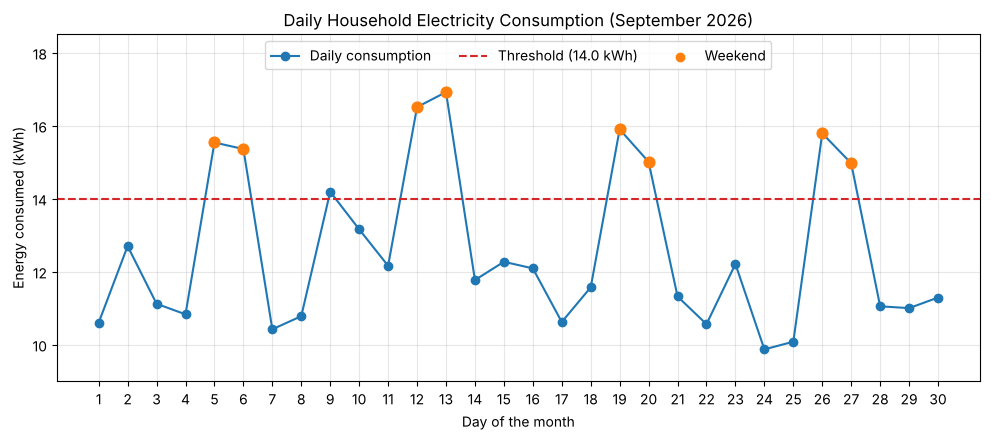

In [8]:
# Plot 1: Daily consumption trend with threshold line
day_numbers = list(range(1, len(data) + 1))
plt.figure(figsize=(10, 4.5))
plt.plot(day_numbers, day_totals, marker="o", color="tab:blue", label="Daily consumption")
plt.axhline(HIGH_USAGE_THRESHOLD, color="tab:red", linestyle="--", label=f"Threshold ({HIGH_USAGE_THRESHOLD} kWh)")
for i in range(len(data)):
    if data[i]["Day"] in WEEKEND_DAYS:
        plt.scatter(day_numbers[i], day_totals[i], color="tab:orange", zorder=3, s=60)
plt.scatter([], [], color="tab:orange", label="Weekend")
plt.title("Daily Household Electricity Consumption (September 2026)")
plt.xlabel("Day of the month")
plt.ylabel("Energy consumed (kWh)")
plt.xticks(day_numbers)
plt.ylim(9, 18.5)
plt.grid(alpha=0.3)
plt.legend(loc="upper center", ncol=3)
plt.tight_layout()
plt.savefig("fig1_daily_trend.png", dpi=150)
plt.show()

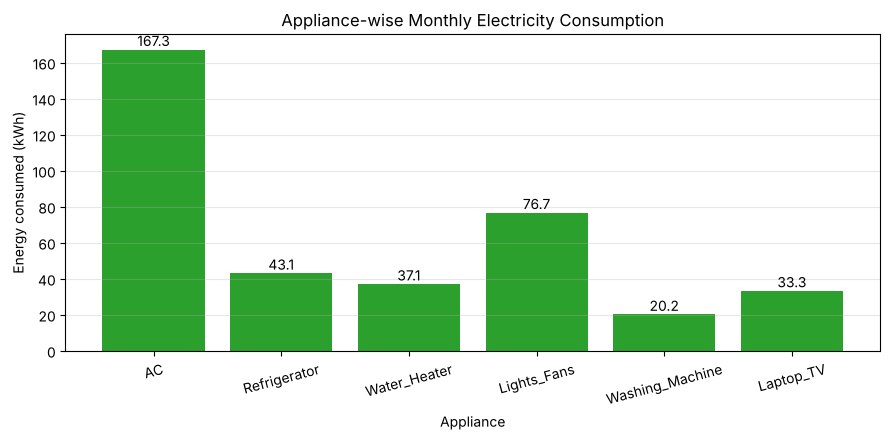

In [9]:
# Plot 2: Appliance-wise monthly consumption (bar chart)
names = list(app_totals.keys())
values = list(app_totals.values())
plt.figure(figsize=(9, 4.5))
bars = plt.bar(names, values, color="tab:green")
for bar, value in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 2, f"{value:.1f}", ha="center")
plt.title("Appliance-wise Monthly Electricity Consumption")
plt.xlabel("Appliance")
plt.ylabel("Energy consumed (kWh)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("fig2_appliance_bar.png", dpi=150)
plt.show()

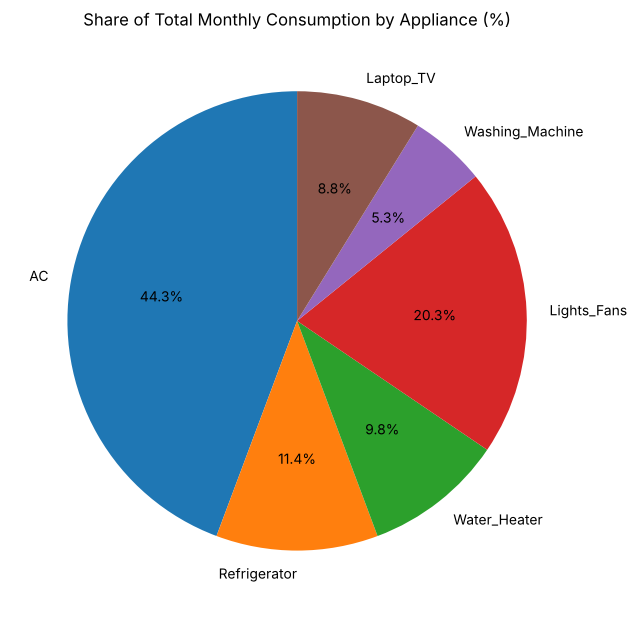

In [10]:
# Plot 3: Share of each appliance in total consumption (pie chart)
plt.figure(figsize=(6.5, 6.5))
plt.pie(values, labels=names, autopct="%1.1f%%", startangle=90)
plt.title("Share of Total Monthly Consumption by Appliance (%)")
plt.tight_layout()
plt.savefig("fig3_share_pie.png", dpi=150)
plt.show()

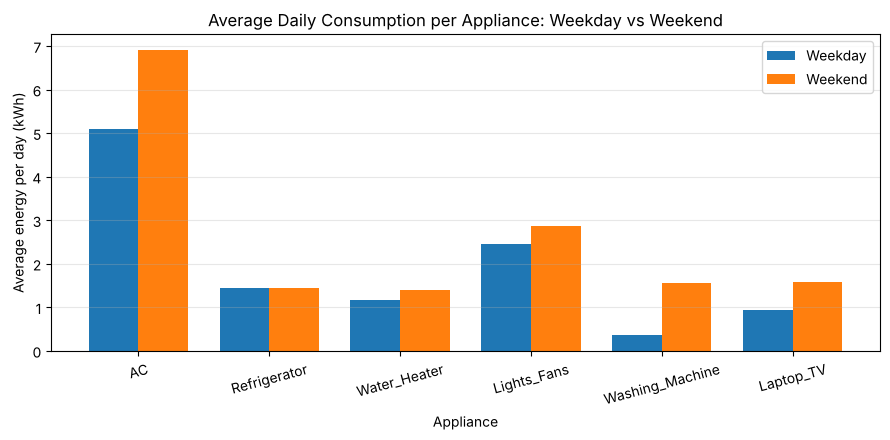

In [11]:
# Plot 4: Weekday vs weekend average, broken down by appliance (grouped bar chart)
weekday_avg, weekend_avg = [], []
for appliance in APPLIANCES:
    wd = [d[appliance] for d in data if d["Day"] not in WEEKEND_DAYS]
    we = [d[appliance] for d in data if d["Day"] in WEEKEND_DAYS]
    weekday_avg.append(sum(wd) / len(wd))
    weekend_avg.append(sum(we) / len(we))

positions = list(range(len(APPLIANCES)))
width = 0.38
plt.figure(figsize=(9, 4.5))
plt.bar([p - width / 2 for p in positions], weekday_avg, width, label="Weekday", color="tab:blue")
plt.bar([p + width / 2 for p in positions], weekend_avg, width, label="Weekend", color="tab:orange")
plt.xticks(positions, APPLIANCES, rotation=15)
plt.title("Average Daily Consumption per Appliance: Weekday vs Weekend")
plt.xlabel("Appliance")
plt.ylabel("Average energy per day (kWh)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("fig4_weekday_weekend.png", dpi=150)
plt.show()

## 7. Observations

1. **The air conditioner dominates consumption.** AC used 167.28 kWh, which is 44.3% of the month's 377.66 kWh (bar and pie charts). Lights and fans come second at 20.3%. Together these two account for almost two-thirds of the bill, so they are the main targets for saving energy.

2. **Weekends are much heavier than weekdays.** Average use was 15.75 kWh/day on weekends against 11.44 kWh/day on weekdays, which is 37.7% higher. The grouped bar chart shows the biggest weekend jump comes from the AC (about 6.9 vs 5.1 kWh/day) and the washing machine, because people are at home for longer.

3. **High-usage days follow a clear pattern.** 9 of 30 days crossed the 14 kWh threshold. Eight of them are Saturdays and Sundays, and the only weekday on the list (9 September) falls in the hot spell of the second week. The highest day was Sunday, 13 September (16.92 kWh), where a weekend and hot weather combined.

4. **Weather affects AC load.** During the hot spell (9–15 September), weekday AC use averaged about 6.2 kWh/day, compared with about 4.8 kWh/day on other weekdays, an increase of roughly 30%. This shows up as the raised section in the middle of the daily trend line.

5. **Base loads are steady.** The refrigerator stayed between 1.27 and 1.64 kWh every day because it runs continuously, so it cannot be "switched off" to save energy. Savings must come from controllable loads like the AC.

6. **The slab tariff makes savings worth more than they appear.** The household reached the third slab (201–400 kWh at Rs 4.70/kWh), giving an estimated bill of Rs 1070.00. Cutting AC use by just 20% (for example by raising the set temperature to 26 °C) reduces consumption to 344.20 kWh and saves about Rs 157 per month (≈15%), because every unit saved comes off the most expensive slab.

## 8. Conclusion
The program successfully turned 30 days of raw readings into a clear picture of household energy use using only basic Python: lists and dictionaries to store data, loops and conditionals to analyse it, a set to classify days, tuples to represent tariff slabs, and six user-defined functions. The analysis shows that the AC is the single largest consumer, weekends and hot days drive the peaks, and modest changes to AC use would give a noticeable saving because of the slab tariff. The same program could be reused with real smart-meter data to monitor consumption every month.


## 9. Acknowledgement
The dataset was simulated by the student; no external dataset was used. The tariff slabs are illustrative values modelled on the slab structure of Tamil Nadu domestic tariffs and are used only for demonstration. Libraries used: Python `csv` (built-in) and `matplotlib`.